<a href="https://colab.research.google.com/github/elchody/E1-EDA/blob/main/E1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación 1 — Calidad, limpieza, transformación y EDA

**Asignatura:** Inteligencia Artificial / Preparación de datos  
**Dataset:** `rendimiento_academico_evaluacion.csv`  
**Integrantes:**

1. Rodrigo Chaura Martínez - rodrigo.chaura2201@alumnos.ubiobio.cl
2. Felipe Chodiman Burdiles - felipe.chodiman2401@alumnos.ubiobio.cl
3. Victor Flores Candia - victor.flores2201@alumnos.ubiobio.cl
4. Carlos Valenzuela Huaiquiman - carlos.valenzuela2301@alumnos.ubiobio.cl


In [ ]:
URL_DATOS = "https://raw.githubusercontent.com/elchody/E1-EDA/refs/heads/main/E1%20-%20EDA/rendimiento_academico_evaluacion.csv"
ARCHIVO_ORIGINAL = "rendimiento_academico_evaluacion.csv"

!wget -q "$URL_DATOS" -O "$ARCHIVO_ORIGINAL"
print(f"Archivo descargado: {ARCHIVO_ORIGINAL}")

Archivo descargado: rendimiento_academico_evaluacion.csv


In [ ]:
%matplotlib inline

import re
import unicodedata
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

# Constantes documentales y lógicas (centralizadas para facilitar una rectificación).
GRADE_MIN = 1.0
GRADE_MAX = 10.0
STUDY_HOURS_MIN = 0.0
STUDY_HOURS_MAX = 168.0  # 24 horas × 7 días; Metadata.md indica horas semanales.

# Se excluye la columna identificadora por indicación de la profesora.
df_original = pd.read_csv(ARCHIVO_ORIGINAL).drop(columns=["StudentID"], errors="ignore")
df = df_original.copy(deep=True)
print(f"Datos cargados: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head())

Datos cargados: 5,100 filas × 10 columnas


,Age,StudyHours,Attendance,PreviousGPA,AssignmentsCompleted,SleepHours,InternetHours,Scholarship,Program,FinalGrade
0,22.000,10.700,83.730,6.090,69.150,6.270,4.390,Sí,Ingeniería Industrial,3.960
1,65.000,9.860,99.600,6.760,76.950,6.520,8.030,No,Ingeniería Informática,5.090
2,26.000,13.430,92.650,6.070,95.990,6.700,6.370,No,Contador Auditor,4.370
3,27.000,20.770,81.730,5.090,90.960,6.160,5.810,No,Contador Auditor,4.020
4,20.000,6.270,70.170,4.840,64.200,6.300,4.100,No,Ingeniería Civil,3.240


## 1. Evaluación de calidad de datos

### 1.1 Caracterización inicial

El análisis utiliza diez variables: `FinalGrade` es la variable objetivo y las nueve columnas restantes son predictoras. Esta separación se respeta durante todo el proceso.

In [ ]:
roles = pd.DataFrame({
    "Variable": df.columns,
    "Rol": ["Target" if c == "FinalGrade" else "Feature" for c in df.columns],
    "Tipo pandas": [str(df[c].dtype) for c in df.columns],
    "Tipo analítico": ["Categórica" if c in ["Scholarship", "Program"] else "Numérica" for c in df.columns],
    "No nulos": [int(df[c].notna().sum()) for c in df.columns],
    "Valores únicos": [int(df[c].nunique(dropna=True)) for c in df.columns],
})

resumen_estructura = pd.DataFrame({
    "Indicador": ["Filas", "Columnas", "Variables numéricas", "Variables categóricas", "Variable objetivo"],
    "Resultado": [
        df.shape[0], df.shape[1],
        int(df.select_dtypes(include=np.number).shape[1]),
        int(df.select_dtypes(exclude=np.number).shape[1]),
        "FinalGrade",
    ],
})
display(resumen_estructura)
display(roles)

,Indicador,Resultado
0,Filas,5100
1,Columnas,10
2,Variables numéricas,8
3,Variables categóricas,2
4,Variable objetivo,FinalGrade


,Variable,Rol,Tipo pandas,Tipo analítico,No nulos,Valores únicos
0,Age,Feature,float64,Numérica,4997,25
1,StudyHours,Feature,float64,Numérica,4919,1838
2,Attendance,Feature,float64,Numérica,4876,2532
3,PreviousGPA,Feature,float64,Numérica,4938,339
4,AssignmentsCompleted,Feature,float64,Numérica,4884,2425
5,SleepHours,Feature,float64,Numérica,4978,622
6,InternetHours,Feature,float64,Numérica,4924,1336
7,Scholarship,Feature,object,Categórica,5019,7
8,Program,Feature,object,Categórica,5030,12
9,FinalGrade,Target,float64,Numérica,5100,499


### 1.2 Valores faltantes

Se informan todas las variables —incluidas las que tienen cero faltantes— para evitar ocultar parte del diagnóstico. El porcentaje se calcula sobre el total de filas originales.

In [ ]:
faltantes = pd.DataFrame({
    "Variable": df.columns,
    "Cantidad faltante": df.isna().sum().values,
    "Porcentaje (%)": (df.isna().mean().values * 100),
}).sort_values(["Cantidad faltante", "Variable"], ascending=[False, True], ignore_index=True)

display(faltantes)
max_faltantes = int(faltantes["Cantidad faltante"].max())
variables_max = faltantes.loc[faltantes["Cantidad faltante"].eq(max_faltantes), "Variable"].tolist()
print(f"Mayor cantidad de faltantes: {max_faltantes:,} en {', '.join(variables_max)}")

,Variable,Cantidad faltante,Porcentaje (%)
0,Attendance,224,4.392
1,AssignmentsCompleted,216,4.235
2,StudyHours,181,3.549
3,InternetHours,176,3.451
4,PreviousGPA,162,3.176
5,SleepHours,122,2.392
6,Age,103,2.020
7,Scholarship,81,1.588
8,Program,70,1.373
9,FinalGrade,0,0.000


Mayor cantidad de faltantes: 224 en Attendance


**Tratamiento justificado:**

- Predictores numéricos: mediana dentro del pipeline, porque es resistente a distribuciones asimétricas y extremos.
- Predictores categóricos: moda después de normalizar escritura, para no crear categorías artificiales.
- `FinalGrade`: no se imputa, ya que inventar la etiqueta introduciría sesgo en una futura tarea supervisada.

### 1.3 Duplicados exactos

In [ ]:
duplicados_exactos = int(df.duplicated(keep="first").sum())

tabla_duplicados = pd.DataFrame({
    "Criterio": ["Filas duplicadas exactas"],
    "Cantidad": [duplicados_exactos],
    "Porcentaje sobre filas (%)": [duplicados_exactos / len(df) * 100],
})
display(tabla_duplicados)
print("Decisión: eliminar duplicados exactos conservando la primera aparición.")

,Criterio,Cantidad,Porcentaje sobre filas (%)
0,Filas duplicadas exactas,100,1.961


Decisión: eliminar duplicados exactos conservando la primera aparición.


### 1.4 Inconsistencias de formato y dominio

Se separan dos conceptos: una **variante de escritura** puede corregirse sin perder información; un **valor imposible** se reemplaza por `NaN` y luego recibe el tratamiento definido según su rol.

In [ ]:
def sin_tildes_mayusculas(valor):
    # Normaliza espacios, mayúsculas y tildes; conserva NaN.
    if pd.isna(valor):
        return np.nan
    texto = unicodedata.normalize("NFKD", str(valor))
    texto = "".join(ch for ch in texto if not unicodedata.combining(ch))
    return re.sub(r"\s+", " ", texto).strip().upper()


PROGRAMAS_VALIDOS = {
    "ADMINISTRACION",
    "CONTADOR AUDITOR",
    "INGENIERIA CIVIL",
    "INGENIERIA INDUSTRIAL",
    "INGENIERIA INFORMATICA",
}


def normalizar_beca(valor):
    texto = sin_tildes_mayusculas(valor)
    if pd.isna(texto):
        return np.nan
    equivalencias = {"SI": "SI", "S": "SI", "YES": "SI", "NO": "NO", "N": "NO"}
    return equivalencias.get(texto, np.nan)


def normalizar_programa(valor):
    texto = sin_tildes_mayusculas(valor)
    return texto if texto in PROGRAMAS_VALIDOS else np.nan


RANGOS_VALIDOS = {
    "Age": (15.0, 100.0, "rango humano plausible para estudiantes"),
    "StudyHours": (STUDY_HOURS_MIN, STUDY_HOURS_MAX, "horas semanales; máximo lógico 24×7"),
    "Attendance": (0.0, 100.0, "porcentaje"),
    "PreviousGPA": (GRADE_MIN, GRADE_MAX, "escala indicada en Metadata.md"),
    "AssignmentsCompleted": (0.0, 100.0, "porcentaje"),
    "SleepHours": (0.0, 24.0, "horas diarias"),
    "InternetHours": (0.0, 24.0, "horas diarias"),
    "FinalGrade": (GRADE_MIN, GRADE_MAX, "escala indicada en Metadata.md"),
}

becas_can = df["Scholarship"].map(normalizar_beca)
programas_can = df["Program"].map(normalizar_programa)

variantes_beca = int((df["Scholarship"].notna() & ~df["Scholarship"].isin(["Sí", "No"])).sum())
programas_escritos = ["Administración", "Contador Auditor", "Ingeniería Civil", "Ingeniería Industrial", "Ingeniería Informática"]
variantes_programa = int((df["Program"].notna() & ~df["Program"].isin(programas_escritos)).sum())
becas_no_reconocidas = int((df["Scholarship"].notna() & becas_can.isna()).sum())
programas_no_reconocidos = int((df["Program"].notna() & programas_can.isna()).sum())

filas_inconsistencias = [
    ["Scholarship", "Mayúsculas, espacios o tildes no canónicas", variantes_beca, "Normalizar a SI/NO"],
    ["Scholarship", "Categoría no reconocible", becas_no_reconocidas, "Convertir a NaN e imputar moda en pipeline"],
    ["Program", "Mayúsculas, espacios o tildes no canónicas", variantes_programa, "Normalizar a cinco programas canónicos"],
    ["Program", "Categoría no reconocible", programas_no_reconocidos, "Convertir a NaN e imputar moda en pipeline"],
]

for variable, (minimo, maximo, fundamento) in RANGOS_VALIDOS.items():
    mascara = df[variable].notna() & ~df[variable].between(minimo, maximo, inclusive="both")
    filas_inconsistencias.append([
        variable,
        f"Fuera de [{minimo:g}, {maximo:g}] ({fundamento})",
        int(mascara.sum()),
        "Convertir a NaN" if variable != "FinalGrade" else "Eliminar fila: no imputar la etiqueta",
    ])

tabla_inconsistencias = pd.DataFrame(
    filas_inconsistencias,
    columns=["Variable", "Problema", "Cantidad", "Tratamiento"],
)
display(tabla_inconsistencias)

,Variable,Problema,Cantidad,Tratamiento
0,Scholarship,"Mayúsculas, espacios o tildes no canónicas",35,Normalizar a SI/NO
1,Scholarship,Categoría no reconocible,0,Convertir a NaN e imputar moda en pipeline
2,Program,"Mayúsculas, espacios o tildes no canónicas",36,Normalizar a cinco programas canónicos
3,Program,Categoría no reconocible,0,Convertir a NaN e imputar moda en pipeline
4,Age,"Fuera de [15, 100] (rango humano plausible par...",0,Convertir a NaN
5,StudyHours,"Fuera de [0, 168] (horas semanales; máximo lóg...",0,Convertir a NaN
6,Attendance,"Fuera de [0, 100] (porcentaje)",20,Convertir a NaN
7,PreviousGPA,"Fuera de [1, 10] (escala indicada en Metadata.md)",0,Convertir a NaN
8,AssignmentsCompleted,"Fuera de [0, 100] (porcentaje)",0,Convertir a NaN
9,SleepHours,"Fuera de [0, 24] (horas diarias)",8,Convertir a NaN


### 1.5 Valores atípicos mediante IQR

El criterio IQR se aplica a las ocho variables numéricas. Un atípico estadístico no es automáticamente un error: se cruza con los rangos documentales/lógicos para distinguir **extremos válidos** de **valores imposibles**.

In [ ]:
df_sin_duplicados = df.drop_duplicates(keep="first").copy()
columnas_numericas_totales = df_sin_duplicados.select_dtypes(include=np.number).columns.tolist()

resumen_iqr = []
mascaras_iqr = {}
for variable in columnas_numericas_totales:
    serie = df_sin_duplicados[variable]
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    mascara_iqr = serie.notna() & ((serie < limite_inf) | (serie > limite_sup))
    mascaras_iqr[variable] = mascara_iqr
    minimo, maximo, _ = RANGOS_VALIDOS[variable]
    mascara_invalida = serie.notna() & ~serie.between(minimo, maximo, inclusive="both")
    resumen_iqr.append({
        "Variable": variable,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior": limite_inf,
        "Límite superior": limite_sup,
        "Atípicos IQR": int(mascara_iqr.sum()),
        "Atípicos e inválidos": int((mascara_iqr & mascara_invalida).sum()),
        "Extremos válidos": int((mascara_iqr & ~mascara_invalida).sum()),
    })

tabla_iqr = pd.DataFrame(resumen_iqr)
display(tabla_iqr)
print(f"Celdas atípicas IQR detectadas: {int(tabla_iqr['Atípicos IQR'].sum()):,}")
print(f"Filas únicas con al menos un atípico IQR: {int(pd.DataFrame(mascaras_iqr).any(axis=1).sum()):,}")

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Atípicos IQR,Atípicos e inválidos,Extremos válidos
0,Age,21.000,26.000,5.000,13.500,33.500,63,0,63
1,StudyHours,8.740,15.450,6.710,-1.325,25.515,48,0,48
2,Attendance,77.520,92.960,15.440,54.360,116.120,27,12,15
3,PreviousGPA,5.220,6.230,1.010,3.705,7.745,20,0,20
4,AssignmentsCompleted,75.852,100.000,24.148,39.631,136.221,16,0,16
5,SleepHours,6.150,7.860,1.710,3.585,10.425,34,8,26
6,InternetHours,3.800,8.390,4.590,-3.085,15.275,141,30,111
7,FinalGrade,3.510,4.870,1.360,1.470,6.910,34,4,30


Celdas atípicas IQR detectadas: 383
Filas únicas con al menos un atípico IQR: 362


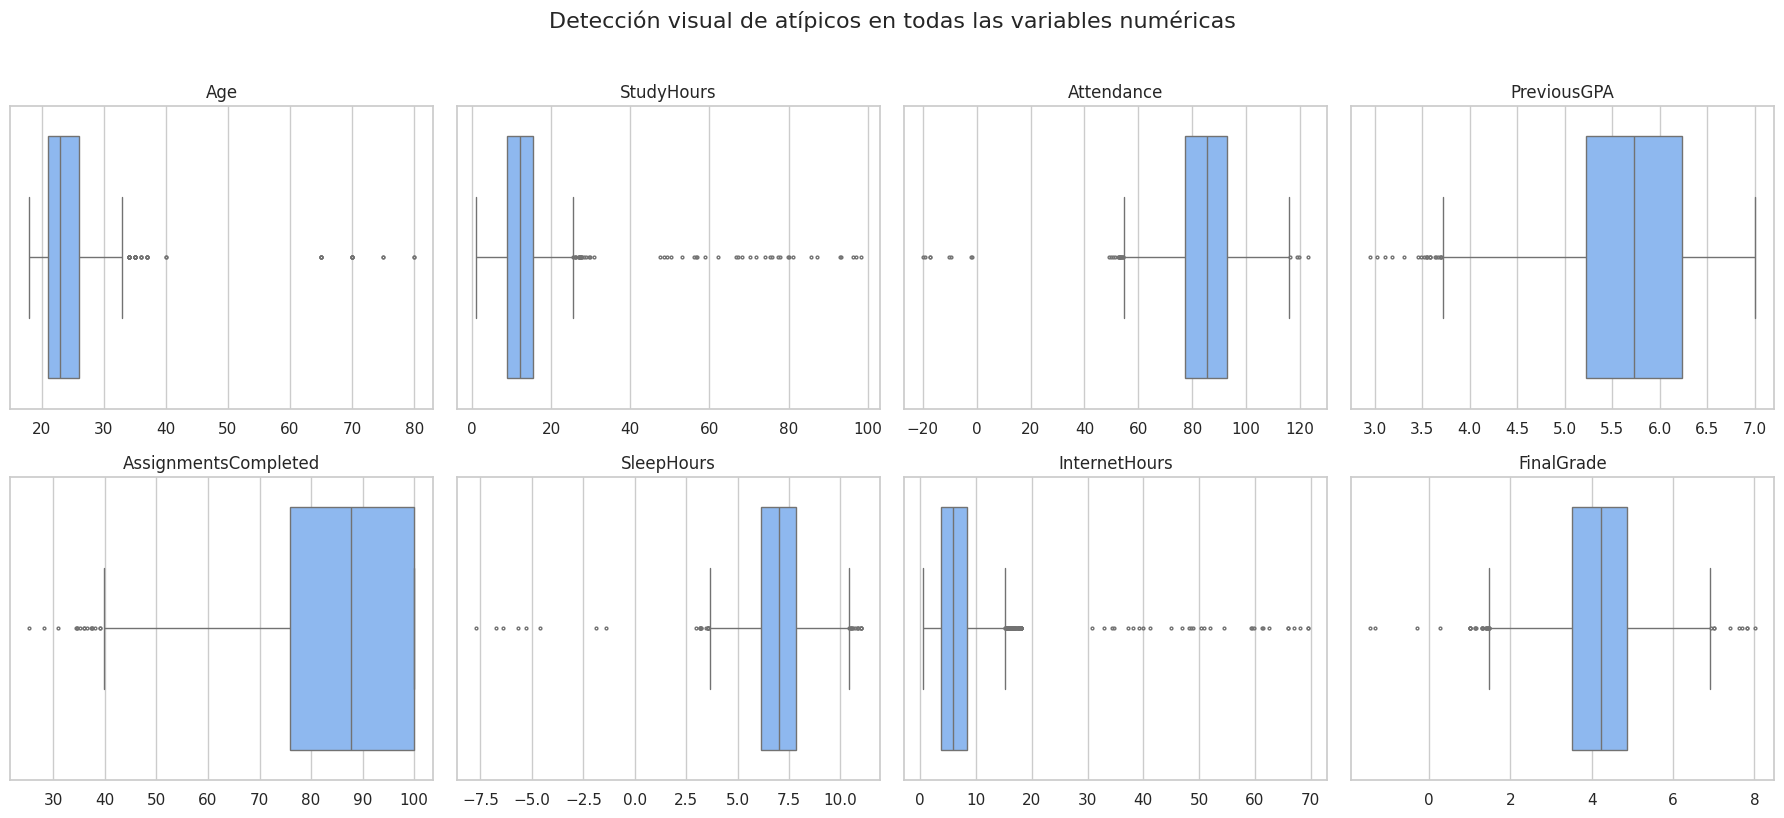

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, variable in zip(axes.ravel(), columnas_numericas_totales):
    sns.boxplot(x=df_sin_duplicados[variable], ax=ax, color="#7EB6FF", fliersize=2)
    ax.set_title(variable)
    ax.set_xlabel("")
fig.suptitle("Detección visual de atípicos en todas las variables numéricas", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Decisión:** los valores imposibles se convierten en faltantes. Los extremos que siguen siendo posibles se conservan —pueden representar estudiantes reales— y su influencia se reduce con `RobustScaler`, que usa mediana e IQR en lugar de media y desviación estándar.

## 2. Base analítica para el EDA

Primero se eliminan copias exactas, se normalizan categorías y se marcan los valores imposibles. Para el EDA se usan observaciones válidas por pares; para el dataset modelable se excluyen únicamente las etiquetas inválidas o ausentes.

In [ ]:
df_analitico = df_sin_duplicados.copy()
df_analitico["Scholarship"] = df_analitico["Scholarship"].map(normalizar_beca)
df_analitico["Program"] = df_analitico["Program"].map(normalizar_programa)

conteo_invalidos_dominio = {}
for variable, (minimo, maximo, _) in RANGOS_VALIDOS.items():
    mascara = df_analitico[variable].notna() & ~df_analitico[variable].between(minimo, maximo, inclusive="both")
    conteo_invalidos_dominio[variable] = int(mascara.sum())
    df_analitico.loc[mascara, variable] = np.nan

filas_objetivo_invalidas = int(df_analitico["FinalGrade"].isna().sum())
df_modelable = df_analitico.loc[df_analitico["FinalGrade"].notna()].copy()

print(f"Filas originales: {len(df):,}")
print(f"Filas tras quitar duplicados exactos: {len(df_sin_duplicados):,}")
print(f"Filas retiradas por target ausente/inválido: {filas_objetivo_invalidas:,}")
print(f"Filas disponibles para EDA modelable: {len(df_modelable):,}")
display(pd.Series(conteo_invalidos_dominio, name="Valores imposibles tras deduplicar").to_frame())

Filas originales: 5,100
Filas tras quitar duplicados exactos: 5,000
Filas retiradas por target ausente/inválido: 4
Filas disponibles para EDA modelable: 4,996


,Valores imposibles tras deduplicar
Age,0
StudyHours,0
Attendance,20
PreviousGPA,0
AssignmentsCompleted,0
SleepHours,8
InternetHours,30
FinalGrade,4


### Decisión adoptada sobre `FinalGrade`

Este entregable **elimina 4 filas cuya etiqueta es inválida** en vez de reemplazarla por la mediana. La razón es metodológica: `FinalGrade` es justamente el valor que un eventual modelo intentaría predecir, por lo que imputarlo fabricaría respuestas y podría sesgar la evaluación. Esta decisión explica el paso de 5.000 registros deduplicados a **4.996 registros modelables** y se mantiene de forma coherente en el pipeline, la comparación final, el README y la presentación.

## 3. Análisis exploratorio de datos (EDA)

### 3.1 Estadísticas descriptivas

In [ ]:
numericas_eda = [c for c in columnas_numericas_totales]
descriptivos = df_modelable[numericas_eda].describe().T
descriptivos["mediana"] = df_modelable[numericas_eda].median()
descriptivos["asimetría"] = df_modelable[numericas_eda].skew()
display(descriptivos)

for variable in ["Scholarship", "Program"]:
    conteos = df_modelable[variable].value_counts(dropna=False).rename("Cantidad").to_frame()
    conteos["Porcentaje (%)"] = conteos["Cantidad"] / len(df_modelable) * 100
    print(f"\nDistribución de {variable}")
    display(conteos)

,count,mean,std,min,25%,50%,75%,max,mediana,asimetría
Age,"4,897.000",23.806,4.671,18.000,21.000,23.000,26.000,80.000,23.000,3.319
StudyHours,"4,816.000",12.423,6.915,1.000,8.740,12.000,15.450,98.329,12.000,4.711
Attendance,"4,756.000",84.714,10.415,49.010,77.558,85.425,92.900,100.000,85.425,-0.394
PreviousGPA,"4,836.000",5.712,0.732,2.950,5.220,5.730,6.230,7.000,5.730,-0.242
AssignmentsCompleted,"4,786.000",85.206,14.223,25.340,75.843,87.730,100.000,100.000,87.730,-0.834
SleepHours,"4,868.000",7.003,1.236,3.000,6.160,7.030,7.860,11.000,7.030,-0.015
InternetHours,"4,796.000",6.395,3.500,0.500,3.790,5.800,8.340,18.000,5.800,0.936
FinalGrade,"4,996.000",4.173,0.985,1.000,3.510,4.230,4.870,8.007,4.230,-0.177



Distribución de Scholarship


,Cantidad,Porcentaje (%)
Scholarship,,
NO,3314,66.333
SI,1602,32.066
NaN,80,1.601



Distribución de Program


,Cantidad,Porcentaje (%)
Program,,
INGENIERIA INFORMATICA,1420,28.423
INGENIERIA INDUSTRIAL,1091,21.837
INGENIERIA CIVIL,986,19.736
ADMINISTRACION,777,15.552
CONTADOR AUDITOR,652,13.050
NaN,70,1.401


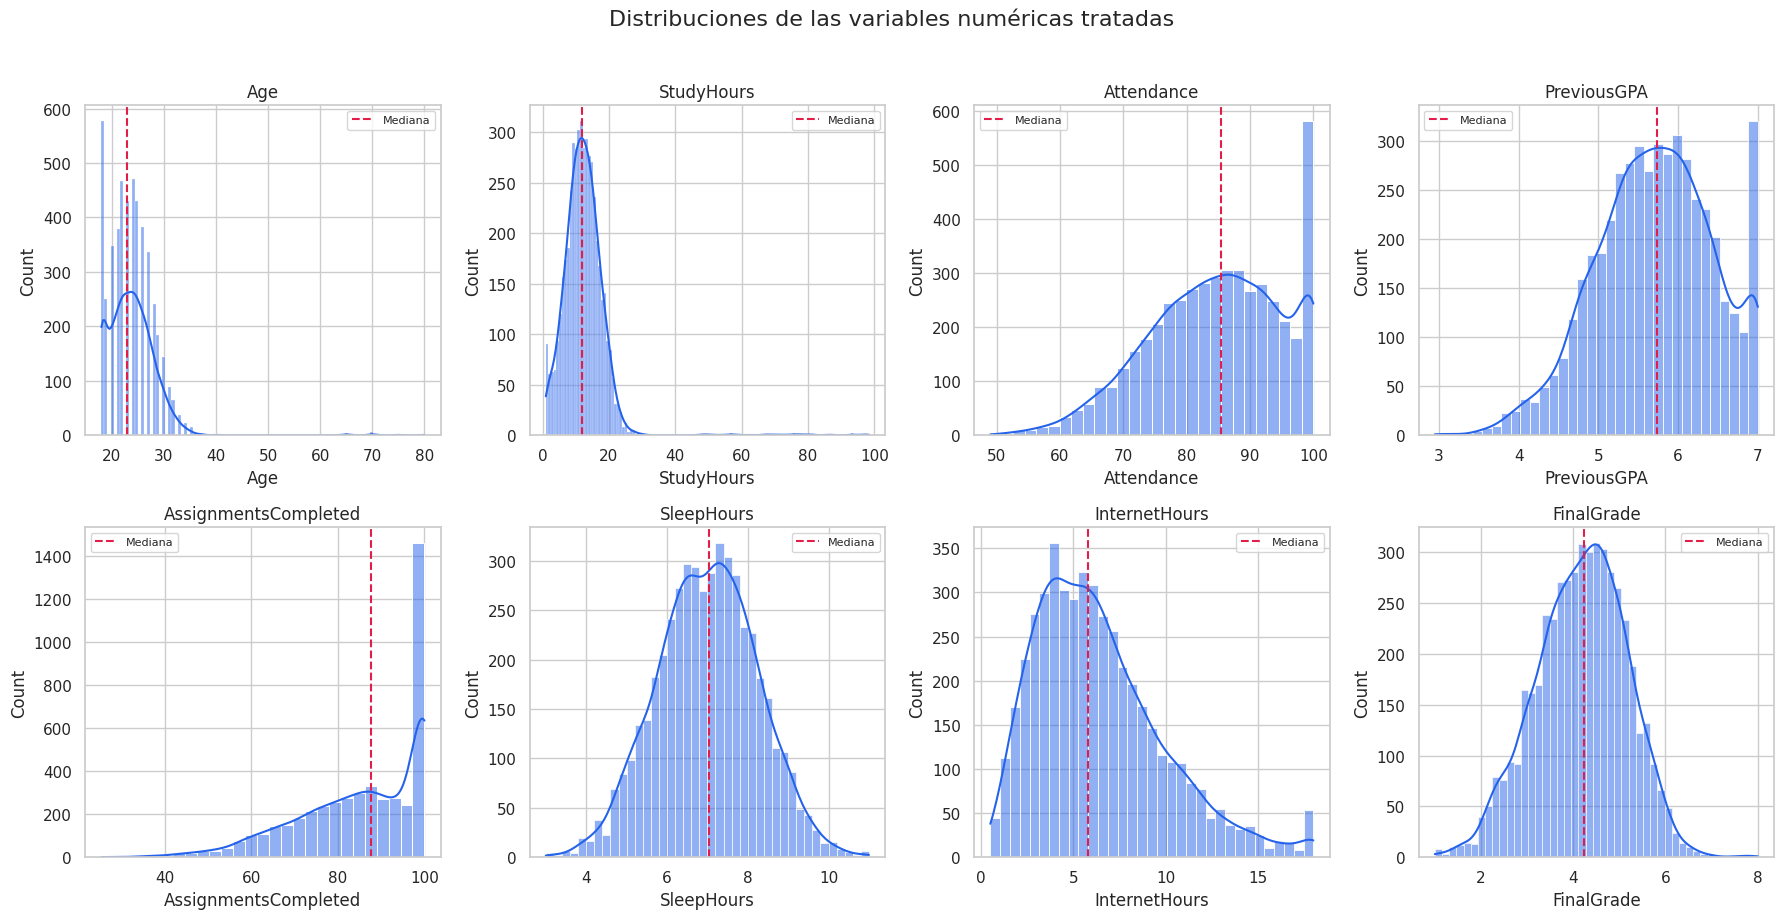

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, variable in zip(axes.ravel(), numericas_eda):
    sns.histplot(df_modelable[variable], kde=True, ax=ax, color="#2563EB")
    ax.axvline(df_modelable[variable].median(), color="#E11D48", linestyle="--", linewidth=1.5, label="Mediana")
    ax.set_title(variable)
    ax.legend(fontsize=8)
fig.suptitle("Distribuciones de las variables numéricas tratadas", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Interpretación — distribuciones numéricas.** La edad se concentra en los primeros años de adultez (mediana cercana a 23) y presenta una cola superior de estudiantes de mayor edad. `StudyHours` muestra asimetría hacia la derecha: existen semanas de estudio intensivo que son atípicas, pero siguen siendo posibles al tratarse de horas semanales. `Attendance`, `PreviousGPA` y `AssignmentsCompleted` se concentran en valores relativamente altos; esta última variable presenta además acumulación en 100%. `SleepHours` se centra cerca de 7 horas, mientras que `InternetHours` conserva una cola derecha después de retirar duraciones diarias imposibles. `FinalGrade` se concentra alrededor de 4,2. La línea roja marca la mediana y permite apreciar la asimetría sin confundir una cola válida con un error de dominio.

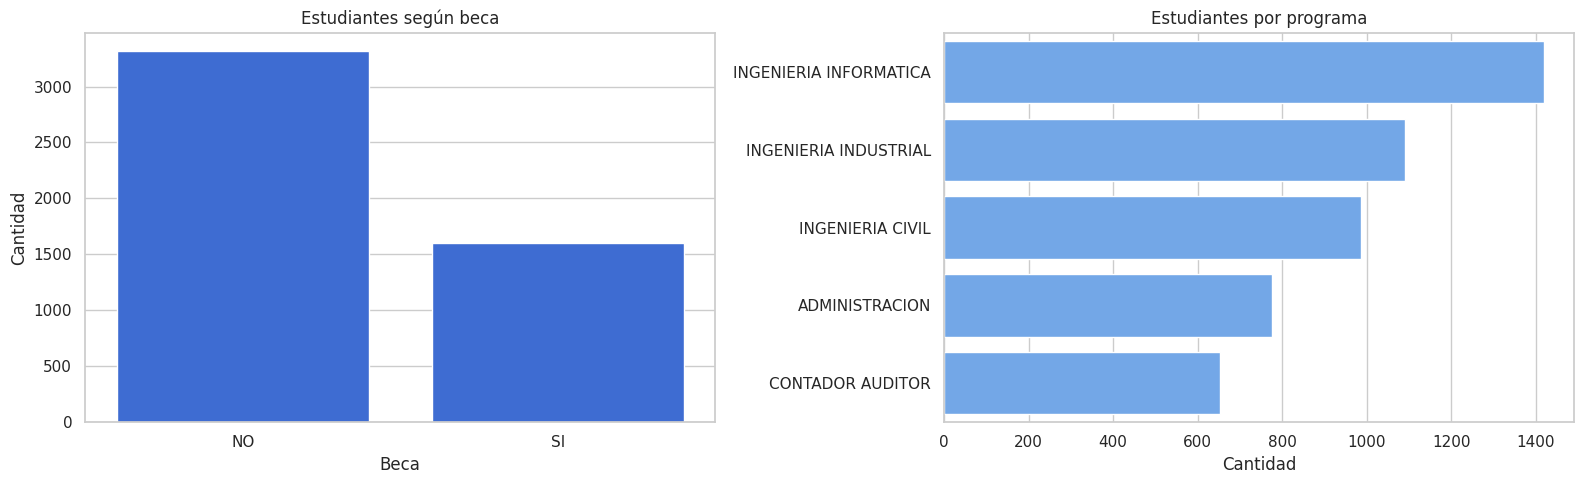

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=df_modelable, x="Scholarship", order=["NO", "SI"], ax=axes[0], color="#2563EB")
axes[0].set_title("Estudiantes según beca")
axes[0].set_xlabel("Beca")
axes[0].set_ylabel("Cantidad")

orden_programas = df_modelable["Program"].value_counts().index
sns.countplot(data=df_modelable, y="Program", order=orden_programas, ax=axes[1], color="#60A5FA")
axes[1].set_title("Estudiantes por programa")
axes[1].set_xlabel("Cantidad")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretación — variables categóricas.** Predominan los estudiantes sin beca: 3.314 registros canónicos corresponden a `NO` y 1.602 a `SI`; los 80 faltantes no aparecen en el gráfico y serán imputados dentro del pipeline. Ingeniería Informática es el programa con más observaciones válidas (1.420) y Contador Auditor el de menor tamaño (652). Esta diferencia de tamaños debe considerarse al comparar grupos, porque una barra más alta representa mayor frecuencia y no necesariamente mejor rendimiento.

### 3.2 Comportamiento de `FinalGrade` y relaciones relevantes

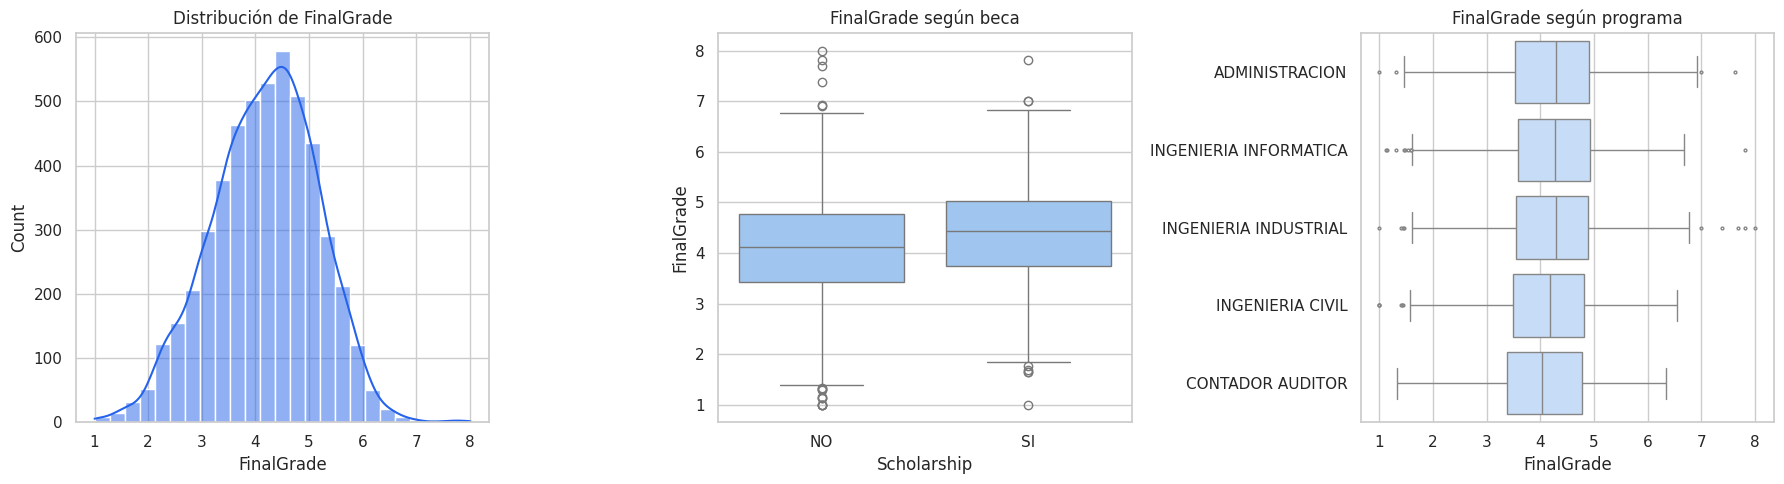

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_modelable["FinalGrade"], kde=True, bins=25, color="#2563EB", ax=axes[0])
axes[0].set_title("Distribución de FinalGrade")

sns.boxplot(data=df_modelable, x="Scholarship", y="FinalGrade", order=["NO", "SI"], color="#93C5FD", ax=axes[1])
axes[1].set_title("FinalGrade según beca")

orden_media_programa = df_modelable.groupby("Program")["FinalGrade"].mean().sort_values(ascending=False).index
sns.boxplot(data=df_modelable, y="Program", x="FinalGrade", order=orden_media_programa, color="#BFDBFE", ax=axes[2], fliersize=2)
axes[2].set_title("FinalGrade según programa")
axes[2].set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretación — nota final por grupos.** `FinalGrade` se concentra cerca de 4,2 y, después de excluir etiquetas imposibles, abarca aproximadamente desde 1,0 hasta 8,0. La distribución del grupo con beca está levemente desplazada hacia notas mayores, aunque existe una superposición considerable con el grupo sin beca. Lo mismo ocurre entre programas: sus cajas se superponen ampliamente y la distancia entre el mayor y el menor promedio es solo cercana a 0,186 puntos. Por ello, beca y programa describen diferencias grupales pequeñas y no determinan por sí solos la nota individual.

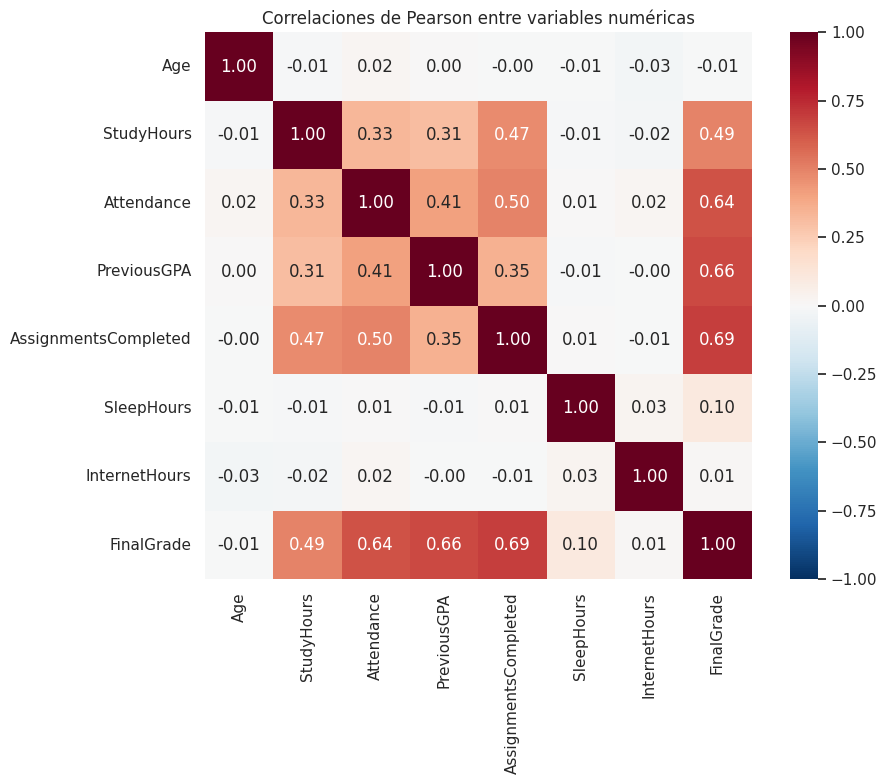

In [ ]:
correlaciones = df_modelable[numericas_eda].corr(method="pearson")
plt.figure(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlaciones de Pearson entre variables numéricas")
plt.tight_layout()
plt.show()

**Interpretación — mapa de correlaciones.** Las asociaciones lineales más altas con `FinalGrade` corresponden a `AssignmentsCompleted` (aprox. 0,690), `PreviousGPA` (aprox. 0,658) y `Attendance` (aprox. 0,639). `StudyHours` presenta una relación positiva moderada (aprox. 0,494), mientras que edad e Internet muestran relaciones lineales cercanas a cero. El mapa ayuda a priorizar variables asociadas, pero ninguna correlación permite concluir causalidad.

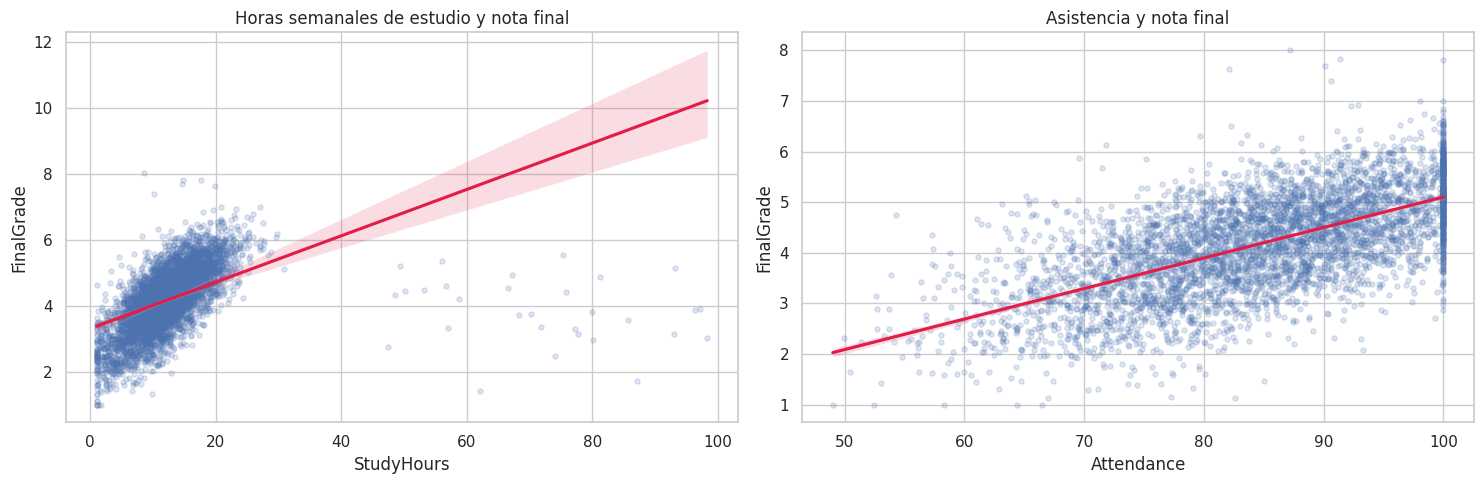

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(data=df_modelable, x="StudyHours", y="FinalGrade", scatter_kws={"alpha": 0.18, "s": 14}, line_kws={"color": "#E11D48"}, ax=axes[0])
axes[0].set_title("Horas semanales de estudio y nota final")

sns.regplot(data=df_modelable, x="Attendance", y="FinalGrade", scatter_kws={"alpha": 0.18, "s": 14}, line_kws={"color": "#E11D48"}, ax=axes[1])
axes[1].set_title("Asistencia y nota final")
plt.tight_layout()
plt.show()

**Interpretación — diagramas de dispersión.** Ambos gráficos presentan pendiente ascendente: mayor estudio semanal y mayor asistencia tienden a acompañarse de una nota final más alta. La relación lineal de asistencia (`r ≈ 0,639`) es más intensa que la de horas de estudio (`r ≈ 0,494`) entre estas dos variables. En `StudyHours`, la correlación de Spearman superior a Pearson sugiere una asociación monotónica que no es perfectamente lineal. La dispersión alrededor de ambas rectas confirma que intervienen otros factores y que estos patrones no prueban causalidad.

## 4. Respuestas a las preguntas de investigación

Las comparaciones usan la base deduplicada, con categorías canónicas y excluyendo solamente valores imposibles en las variables involucradas.

### Pregunta 1 — ¿Cómo cambia la nota final promedio según la tenencia de beca?

In [ ]:
beca_resumen = df_modelable.groupby("Scholarship", dropna=False)["FinalGrade"].agg(Media="mean", Mediana="median", N="count").sort_index()
display(beca_resumen)

media_si = beca_resumen.loc["SI", "Media"]
media_no = beca_resumen.loc["NO", "Media"]
diferencia_beca = media_si - media_no
grupo_mayor_beca = "con beca" if diferencia_beca > 0 else "sin beca"
print(f"Diferencia SI − NO: {diferencia_beca:.3f} puntos. El promedio mayor corresponde al grupo {grupo_mayor_beca}.")

,Media,Mediana,N
Scholarship,,,
NO,4.078,4.120,3314
SI,4.371,4.430,1602
NaN,4.178,4.200,80


Diferencia SI − NO: 0.293 puntos. El promedio mayor corresponde al grupo con beca.


### Pregunta 2 — ¿Qué programa presenta la mayor y la menor nota final promedio?

In [ ]:
programa_resumen = df_modelable.groupby("Program")["FinalGrade"].agg(Media="mean", Mediana="median", N="count").sort_values("Media", ascending=False)
display(programa_resumen)

programa_max = programa_resumen["Media"].idxmax()
programa_min = programa_resumen["Media"].idxmin()
diferencia_programa = programa_resumen.loc[programa_max, "Media"] - programa_resumen.loc[programa_min, "Media"]
print(f"Mayor promedio: {programa_max} ({programa_resumen.loc[programa_max, 'Media']:.3f}).")
print(f"Menor promedio: {programa_min} ({programa_resumen.loc[programa_min, 'Media']:.3f}).")
print(f"Diferencia entre extremos: {diferencia_programa:.3f} puntos.")

,Media,Mediana,N
Program,,,
ADMINISTRACION,4.232,4.290,777
INGENIERIA INFORMATICA,4.231,4.270,1420
INGENIERIA INDUSTRIAL,4.203,4.290,1091
INGENIERIA CIVIL,4.110,4.185,986
CONTADOR AUDITOR,4.046,4.040,652


Mayor promedio: ADMINISTRACION (4.232).
Menor promedio: CONTADOR AUDITOR (4.046).
Diferencia entre extremos: 0.186 puntos.


### Pregunta 3 — ¿Qué relación existe entre `StudyHours` y `FinalGrade`?

In [ ]:
def intensidad_correlacion(r):
    valor = abs(r)
    if valor < 0.20:
        return "muy débil"
    if valor < 0.40:
        return "débil"
    if valor < 0.60:
        return "moderada"
    if valor < 0.80:
        return "fuerte"
    return "muy fuerte"

pares_estudio = df_modelable[["StudyHours", "FinalGrade"]].dropna()
r_estudio = pares_estudio.corr(method="pearson").iloc[0, 1]
rho_estudio = pares_estudio.corr(method="spearman").iloc[0, 1]
direccion_estudio = "positiva" if r_estudio > 0 else "negativa"

print(f"Observaciones completas: {len(pares_estudio):,}")
print(f"Pearson r = {r_estudio:.3f}: relación {direccion_estudio} y {intensidad_correlacion(r_estudio)}.")
print(f"Spearman ρ = {rho_estudio:.3f}, lo que respalda una asociación monotónica positiva.")
print("Interpretación: más horas de estudio tienden a asociarse con una nota mayor; correlación no implica causalidad.")

Observaciones completas: 4,816
Pearson r = 0.494: relación positiva y moderada.
Spearman ρ = 0.711, lo que respalda una asociación monotónica positiva.
Interpretación: más horas de estudio tienden a asociarse con una nota mayor; correlación no implica causalidad.


### Pregunta 4 — ¿Cómo se relaciona `Attendance` con `FinalGrade` estadística y gráficamente?

In [ ]:
pares_asistencia = df_modelable[["Attendance", "FinalGrade"]].dropna()
r_asistencia = pares_asistencia.corr(method="pearson").iloc[0, 1]
rho_asistencia = pares_asistencia.corr(method="spearman").iloc[0, 1]
direccion_asistencia = "positiva" if r_asistencia > 0 else "negativa"

print(f"Observaciones completas: {len(pares_asistencia):,}")
print(f"Pearson r = {r_asistencia:.3f}: relación {direccion_asistencia} y {intensidad_correlacion(r_asistencia)}.")
print(f"Spearman ρ = {rho_asistencia:.3f}.")
print("El diagrama de dispersión y la recta de tendencia mostrados arriba confirman visualmente una pendiente positiva.")

Observaciones completas: 4,756
Pearson r = 0.639: relación positiva y fuerte.
Spearman ρ = 0.632.
El diagrama de dispersión y la recta de tendencia mostrados arriba confirman visualmente una pendiente positiva.


### Tres conclusiones generales del EDA

1. **La asistencia es el predictor lineal más asociado con la nota final entre las relaciones solicitadas:** `Attendance` presenta una correlación positiva de aproximadamente **0,639**, superior a la de `StudyHours` (aprox. **0,494**).
2. **La beca se asocia con una diferencia pequeña pero consistente:** estudiantes con beca promedian cerca de **0,293 puntos** más que quienes no tienen beca; esto describe asociación y no demuestra causalidad.
3. **Las diferencias promedio entre programas son acotadas:** el máximo corresponde a **Administración** y el mínimo a **Contador Auditor**, con una brecha aproximada de **0,186 puntos**. Las distribuciones se superponen ampliamente, por lo que el programa por sí solo explica poco de la variabilidad individual.

## 5. Tratamiento y transformación

### 5.1 Decisiones consolidadas

In [ ]:
decisiones = pd.DataFrame([
    ["Duplicados exactos", "Eliminar copias, conservar primera aparición", "Evita ponderar dos veces el mismo registro"],
    ["Categorías", "Normalizar espacios, mayúsculas y tildes", "Evita niveles artificiales"],
    ["Valores numéricos imposibles", "Convertir a NaN", "Se distinguen errores de extremos válidos"],
    ["FinalGrade inválido/ausente", "Eliminar fila", "No se deben inventar etiquetas"],
    ["Faltantes numéricos de X", "Imputar mediana", "Es resistente a asimetría y atípicos"],
    ["Faltantes categóricos de X", "Imputar moda", "Conserva una categoría válida frecuente"],
    ["Atípicos válidos", "Conservar y usar RobustScaler", "Reduce su influencia sin borrar casos plausibles"],
    ["Categóricas", "OneHotEncoder", "Representación numérica sin imponer orden"],
], columns=["Problema", "Tratamiento", "Justificación"])
display(decisiones)

,Problema,Tratamiento,Justificación
0,Duplicados exactos,"Eliminar copias, conservar primera aparición",Evita ponderar dos veces el mismo registro
1,Categorías,"Normalizar espacios, mayúsculas y tildes",Evita niveles artificiales
2,Valores numéricos imposibles,Convertir a NaN,Se distinguen errores de extremos válidos
3,FinalGrade inválido/ausente,Eliminar fila,No se deben inventar etiquetas
4,Faltantes numéricos de X,Imputar mediana,Es resistente a asimetría y atípicos
5,Faltantes categóricos de X,Imputar moda,Conserva una categoría válida frecuente
6,Atípicos válidos,Conservar y usar RobustScaler,Reduce su influencia sin borrar casos plausibles
7,Categóricas,OneHotEncoder,Representación numérica sin imponer orden


### 5.2 Separación de predictores y objetivo

In [ ]:
TARGET = "FinalGrade"
FEATURES_NUMERICAS = [
    "Age", "StudyHours", "Attendance", "PreviousGPA",
    "AssignmentsCompleted", "SleepHours", "InternetHours",
]
FEATURES_CATEGORICAS = ["Scholarship", "Program"]
FEATURES = FEATURES_NUMERICAS + FEATURES_CATEGORICAS

X = df_modelable[FEATURES].reset_index(drop=True)
y = df_modelable[TARGET].reset_index(drop=True)

print(f"X: {X.shape[0]:,} filas × {X.shape[1]} predictores")
print(f"y: {y.shape[0]:,} valores de {TARGET}, rango observado [{y.min():.3f}, {y.max():.3f}]")

X: 4,996 filas × 9 predictores
y: 4,996 valores de FinalGrade, rango observado [1.000, 8.007]


### 5.3 Pipeline con `ColumnTransformer`

`FinalGrade` queda fuera del pipeline. Para una futura evaluación predictiva, este preprocesador debe ajustarse **solo con el conjunto de entrenamiento** o dentro de validación cruzada. Aquí se ajusta sobre la base modelable completa únicamente para generar el artefacto limpio exigido.

In [ ]:
pipeline_numerico = Pipeline(steps=[
    ("imputacion_mediana", SimpleImputer(strategy="median")),
    ("escala_robusta", RobustScaler()),
])

pipeline_categorico = Pipeline(steps=[
    ("imputacion_moda", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocesador = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico, FEATURES_NUMERICAS),
        ("cat", pipeline_categorico, FEATURES_CATEGORICAS),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_transformado = preprocesador.fit_transform(X)
nombres_transformados = preprocesador.get_feature_names_out()

df_features_transformadas = pd.DataFrame(X_transformado, columns=nombres_transformados)
df_limpio = pd.concat(
    [df_features_transformadas, y.rename(TARGET)],
    axis=1,
)

print(f"Matriz transformada: {X_transformado.shape[0]:,} filas × {X_transformado.shape[1]} variables")
print(f"Dataset final con predictores y target: {df_limpio.shape[0]:,} filas × {df_limpio.shape[1]} columnas")
display(df_limpio.head())

Matriz transformada: 4,996 filas × 14 variables
Dataset final con predictores y target: 4,996 filas × 15 columnas


,Age,StudyHours,Attendance,PreviousGPA,AssignmentsCompleted,SleepHours,InternetHours,Scholarship_NO,Scholarship_SI,Program_ADMINISTRACION,Program_CONTADOR AUDITOR,Program_INGENIERIA CIVIL,Program_INGENIERIA INDUSTRIAL,Program_INGENIERIA INFORMATICA,FinalGrade
0,-0.200,-0.204,-0.116,0.370,-0.798,-0.461,-0.325,0.000,1.000,0.000,0.000,0.000,1.000,0.000,3.960
1,8.400,-0.336,0.971,1.059,-0.463,-0.309,0.514,1.000,0.000,0.000,0.000,0.000,0.000,1.000,5.090
2,0.600,0.225,0.495,0.350,0.355,-0.200,0.131,1.000,0.000,0.000,1.000,0.000,0.000,0.000,4.370
3,0.800,1.378,-0.253,-0.658,0.139,-0.527,0.002,1.000,0.000,0.000,1.000,0.000,0.000,0.000,4.020
4,-0.600,-0.901,-1.045,-0.915,-1.011,-0.442,-0.391,1.000,0.000,0.000,0.000,1.000,0.000,0.000,3.240


## 6. Verificación de calidad final y comparación

In [ ]:
matriz_numerica = df_limpio.to_numpy(dtype=float)

columnas_beca_ohe = [c for c in df_limpio.columns if c.startswith("Scholarship_")]
columnas_programa_ohe = [c for c in df_limpio.columns if c.startswith("Program_")]

controles = {
    "Sin valores faltantes": int(df_limpio.isna().sum().sum()) == 0,
    "Sin infinitos": bool(np.isfinite(matriz_numerica).all()),
    "Sin filas duplicadas": int(df_limpio.duplicated().sum()) == 0,
    "FinalGrade dentro de 1–10": bool(df_limpio[TARGET].between(GRADE_MIN, GRADE_MAX).all()),
    "One-hot Scholarship válido": bool(np.isclose(df_limpio[columnas_beca_ohe].sum(axis=1), 1).all()),
    "One-hot Program válido": bool(np.isclose(df_limpio[columnas_programa_ohe].sum(axis=1), 1).all()),
    "FinalGrade no fue escalado": bool(np.allclose(df_limpio[TARGET].to_numpy(), y.to_numpy())),
}

tabla_controles = pd.DataFrame({"Control": controles.keys(), "Cumple": controles.values()})
display(tabla_controles)
assert all(controles.values()), "Falló al menos un control de calidad final."
print("Todos los controles de calidad final fueron superados.")

,Control,Cumple
0,Sin valores faltantes,True
1,Sin infinitos,True
2,Sin filas duplicadas,True
3,FinalGrade dentro de 1–10,True
4,One-hot Scholarship válido,True
5,One-hot Program válido,True
6,FinalGrade no fue escalado,True


Todos los controles de calidad final fueron superados.


In [ ]:
valores_imposibles_originales = int(sum(
    (df[var].notna() & ~df[var].between(minimo, maximo, inclusive="both")).sum()
    for var, (minimo, maximo, _) in RANGOS_VALIDOS.items()
))

comparacion = pd.DataFrame([
    ["Filas", len(df), len(df_limpio), f"−{len(df) - len(df_limpio):,}: duplicados exactos y targets inválidos"],
    ["Columnas", df.shape[1], df_limpio.shape[1], "Aumentan por one-hot; se conserva el target"],
    ["Valores faltantes (celdas)", int(df.isna().sum().sum()), int(df_limpio.isna().sum().sum()), "Imputados solo en X"],
    ["Duplicados exactos", duplicados_exactos, int(df_limpio.duplicated().sum()), "Eliminados"],
    ["Valores imposibles (celdas)", valores_imposibles_originales, 0, "Imputados en X o filas retiradas si era el target"],
    ["Atípicos IQR (celdas)", int(tabla_iqr["Atípicos IQR"].sum()), "Conservados si son válidos", "Tratados con RobustScaler en las 7 features numéricas"],
    ["Categorías de Scholarship", int(df["Scholarship"].nunique(dropna=True)), len(columnas_beca_ohe), "Canónicas: NO y SI"],
    ["Categorías de Program", int(df["Program"].nunique(dropna=True)), len(columnas_programa_ohe), "Cinco programas canónicos"],
], columns=["Indicador", "Original", "Final", "Resultado/decisión"])
display(comparacion)

,Indicador,Original,Final,Resultado/decisión
0,Filas,5100,4996,−104: duplicados exactos y targets inválidos
1,Columnas,10,15,Aumentan por one-hot; se conserva el target
2,Valores faltantes (celdas),1335,0,Imputados solo en X
3,Duplicados exactos,100,0,Eliminados
4,Valores imposibles (celdas),63,0,Imputados en X o filas retiradas si era el target
5,Atípicos IQR (celdas),383,Conservados si son válidos,Tratados con RobustScaler en las 7 features nu...
6,Categorías de Scholarship,7,2,Canónicas: NO y SI
7,Categorías de Program,12,5,Cinco programas canónicos


## 7. Exportación

El CSV contiene únicamente las variables predictoras transformadas y `FinalGrade` sin escalar, lo que mantiene la etiqueta interpretable.

In [ ]:
ARCHIVO_LIMPIO = "rendimiento_academico_limpio.csv"
df_limpio.to_csv(ARCHIVO_LIMPIO, index=False, encoding="utf-8")

ruta_salida = Path(ARCHIVO_LIMPIO)
print(f"Archivo exportado: {ruta_salida.name}")
print(f"Tamaño: {ruta_salida.stat().st_size:,} bytes")
print(f"Dimensiones guardadas: {pd.read_csv(ruta_salida).shape}")

Archivo exportado: rendimiento_academico_limpio.csv
Tamaño: 759,496 bytes
Dimensiones guardadas: (4996, 15)


## 8. Cierre

El flujo queda reproducible: descarga, diagnóstico, decisiones justificadas, EDA, transformación con pipeline, verificación y exportación. El archivo final no contiene faltantes, infinitos, duplicados ni etiquetas fuera de la escala documentada; los extremos plausibles se preservan y se tratan con escalamiento robusto.